In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Load cleaned dataset
df = pd.read_csv(
    "../dataset/APL_Logistics_cleaned.csv",
    encoding="latin1"
)

print("Cleaned dataset loaded successfully!")

print("Dataset Shape:", df.shape)

Cleaned dataset loaded successfully!
Dataset Shape: (180519, 19)


In [2]:
numerical_columns = df.select_dtypes(
    include=np.number
).columns

print("Numerical Columns:")

for col in numerical_columns:
    print(col)

Numerical Columns:
Days for shipment (scheduled)
Late_delivery_risk
Latitude
Longitude
Order Item Discount
Order Item Discount Rate
Order Item Product Price
Order Item Quantity
Product Price


In [3]:
df[numerical_columns].describe()

,Days for shipment (scheduled),Late_delivery_risk,Latitude,Longitude,Order Item Discount,Order Item Discount Rate,Order Item Product Price,Order Item Quantity,Product Price
count,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000
mean,2.931847,0.548291,29.719955,-84.915675,20.664741,0.101668,141.232547,2.127638,141.232547
std,1.374449,0.497664,9.813646,21.433241,21.800901,0.070415,139.732489,1.453451,139.732489
min,0.000000,0.000000,-33.937553,-158.025986,0.000000,0.000000,9.990000,1.000000,9.990000
25%,2.000000,0.000000,18.265432,-98.446312,5.400000,0.040000,50.000000,1.000000,50.000000
50%,4.000000,1.000000,33.144863,-76.847908,14.000000,0.100000,59.990000,1.000000,59.990000
75%,4.000000,1.000000,39.279617,-66.370583,29.990000,0.160000,199.990000,3.000000,199.990000
max,4.000000,1.000000,48.781933,115.263077,500.000000,0.250000,1999.990000,5.000000,1999.990000


In [4]:
df['Shipping_Pressure_Index'] = (
    df['Order Item Quantity'] /
    (df['Days for shipment (scheduled)'] + 1)
)

print(df[
    ['Order Item Quantity',
     'Days for shipment (scheduled)',
     'Shipping_Pressure_Index']
].head())

   Order Item Quantity  Days for shipment (scheduled)  Shipping_Pressure_Index
0                    5                              4                      1.0
1                    5                              4                      1.0
2                    1                              4                      0.2
3                    1                              4                      0.2
4                    1                              4                      0.2


In [5]:
def order_complexity(quantity):

    if quantity <= 2:
        return "Low"

    elif quantity <= 5:
        return "Medium"

    else:
        return "High"


df['Order_Complexity'] = (
    df['Order Item Quantity']
    .apply(order_complexity)
)

print(df[
    ['Order Item Quantity', 'Order_Complexity']
].head(10))

   Order Item Quantity Order_Complexity
0                    5           Medium
1                    5           Medium
2                    1              Low
3                    1              Low
4                    1              Low
5                    1              Low
6                    3           Medium
7                    2              Low
8                    1              Low
9                    2              Low


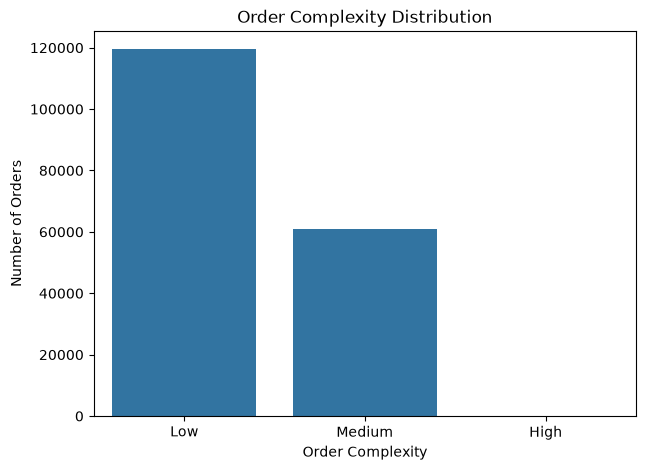

In [6]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='Order_Complexity',
    order=['Low', 'Medium', 'High']
)

plt.title('Order Complexity Distribution')
plt.xlabel('Order Complexity')
plt.ylabel('Number of Orders')

plt.show()

In [7]:
def shipping_duration(days):

    if days <= 2:
        return "Short"

    elif days <= 4:
        return "Medium"

    else:
        return "Long"


df['Scheduled_Duration_Category'] = (
    df['Days for shipment (scheduled)']
    .apply(shipping_duration)
)

print(df[
    ['Days for shipment (scheduled)',
     'Scheduled_Duration_Category']
].head(10))

   Days for shipment (scheduled) Scheduled_Duration_Category
0                              4                      Medium
1                              4                      Medium
2                              4                      Medium
3                              4                      Medium
4                              4                      Medium
5                              4                      Medium
6                              4                      Medium
7                              4                      Medium
8                              4                      Medium
9                              4                      Medium


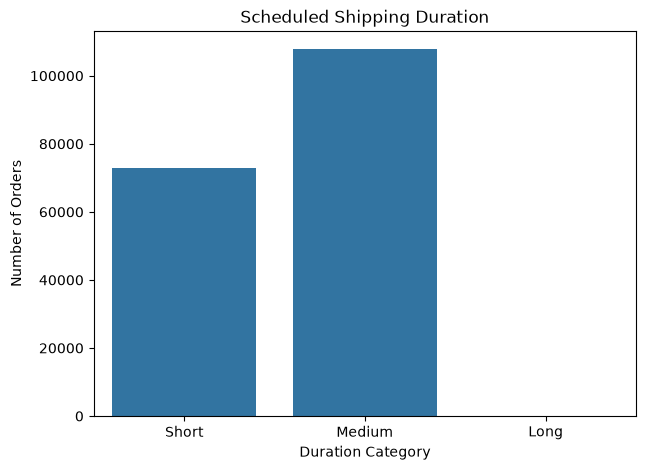

In [8]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='Scheduled_Duration_Category',
    order=['Short', 'Medium', 'Long']
)

plt.title('Scheduled Shipping Duration')
plt.xlabel('Duration Category')
plt.ylabel('Number of Orders')

plt.show()

In [9]:
print(df['Shipping Mode'].value_counts())

Shipping Mode
Standard Class    107752
Second Class       35216
First Class        27814
Same Day            9737
Name: count, dtype: int64


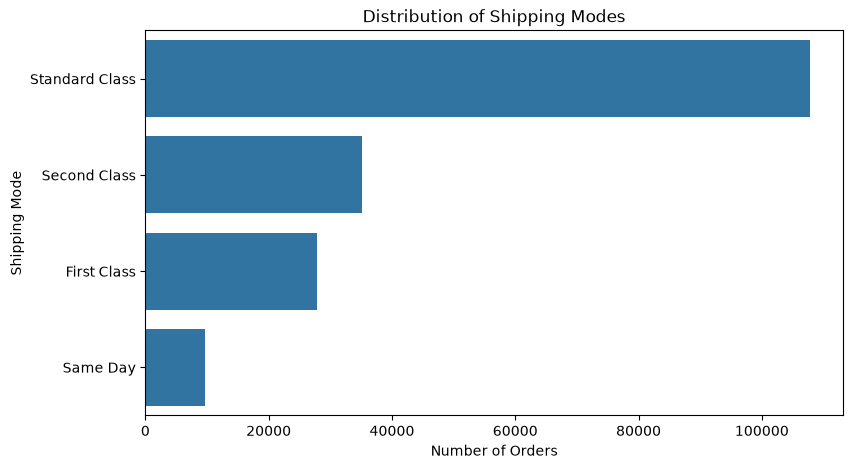

In [10]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    y='Shipping Mode',
    order=df['Shipping Mode'].value_counts().index
)

plt.title('Distribution of Shipping Modes')
plt.xlabel('Number of Orders')
plt.ylabel('Shipping Mode')

plt.show()

In [11]:
regional_columns = [
    'Market',
    'Order Region',
    'Order Country',
    'Order State'
]

for col in regional_columns:

    print("\nColumn:", col)

    print(df[col].value_counts().head(10))


Column: Market
Market
LATAM           51594
Europe          50252
Pacific Asia    41260
USCA            25799
Africa          11614
Name: count, dtype: int64

Column: Order Region
Order Region
Central America    28341
Western Europe     27109
South America      14935
Oceania            10148
Northern Europe     9792
Southeast Asia      9539
Southern Europe     9431
Caribbean           8318
West of USA         7993
South Asia          7731
Name: count, dtype: int64

Column: Order Country
Order Country
Estados Unidos    24840
Francia           13222
MÃ©xico           13172
Alemania           9564
Australia          8497
Brasil             7987
Reino Unido        7302
China              5758
Italia             4989
India              4783
Name: count, dtype: int64

Column: Order State
Order State
Inglaterra                     6722
California                     4966
Isla de Francia                4580
Renania del Norte-Westfalia    3303
San Salvador                   3055
Nueva York    

In [12]:
regional_analysis = (
    df.groupby('Order Region')['Late_delivery_risk']
    .agg(['count', 'mean'])
    .reset_index()
)

regional_analysis['Late_Rate_Percentage'] = (
    regional_analysis['mean'] * 100
)

regional_analysis = regional_analysis.sort_values(
    'Late_Rate_Percentage',
    ascending=False
)

display(regional_analysis)

,Order Region,count,mean,Late_Rate_Percentage
2,Central Africa,1677,0.579606,57.960644
13,South Asia,7731,0.562670,56.266977
5,East Africa,1852,0.559395,55.939525
22,Western Europe,27109,0.558486,55.848611
14,South of USA,4045,0.557726,55.772559
8,Eastern Europe,3920,0.556633,55.663265
6,East of USA,6915,0.556616,55.661605
15,Southeast Asia,9539,0.555299,55.529930
4,Central Asia,553,0.553345,55.334539
20,West Asia,6009,0.552837,55.283741


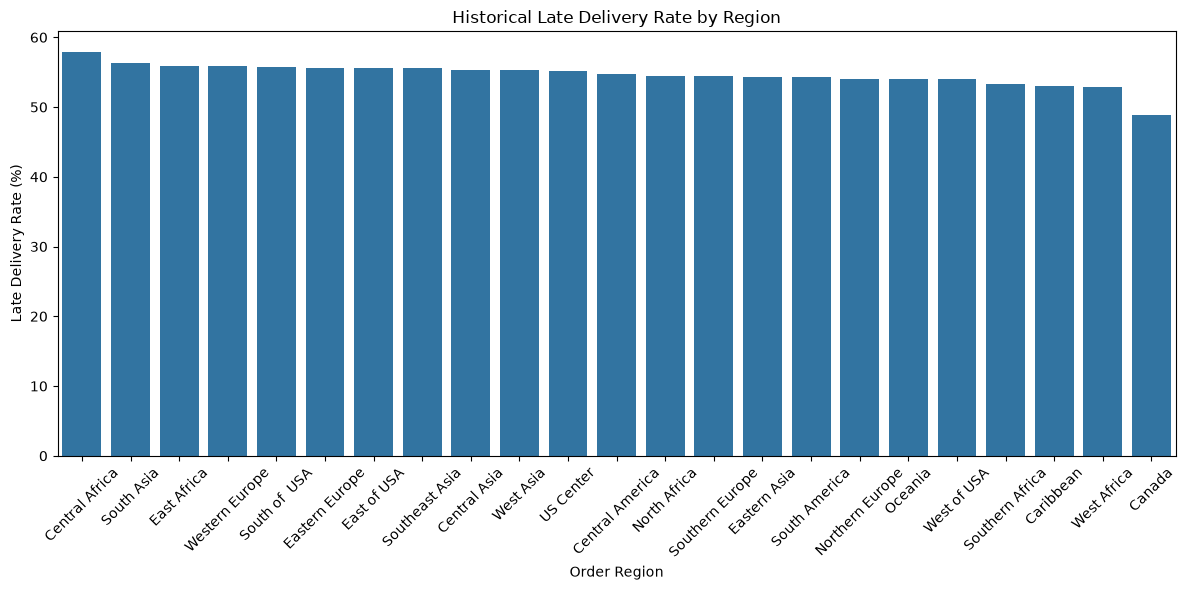

In [13]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=regional_analysis,
    x='Order Region',
    y='Late_Rate_Percentage'
)

plt.xticks(rotation=45)

plt.title('Historical Late Delivery Rate by Region')
plt.xlabel('Order Region')
plt.ylabel('Late Delivery Rate (%)')

plt.tight_layout()
plt.show()

In [14]:
new_features = [
    'Shipping_Pressure_Index',
    'Order_Complexity',
    'Scheduled_Duration_Category'
]

print("New Features Created:\n")

for feature in new_features:

    print("\n", feature)

    print(df[feature].value_counts().head(10))

New Features Created:


 Shipping_Pressure_Index
Shipping_Pressure_Index
0.200000    59184
1.000000    24402
0.333333    19426
0.500000    15270
0.400000    12249
0.800000    12160
0.600000    12059
2.000000     4195
1.333333     3999
1.666667     3963
Name: count, dtype: int64

 Order_Complexity
Order_Complexity
Low       119449
Medium     61070
Name: count, dtype: int64

 Scheduled_Duration_Category
Scheduled_Duration_Category
Medium    107752
Short      72767
Name: count, dtype: int64


In [15]:
df[
    [
        'Order Item Quantity',
        'Days for shipment (scheduled)',
        'Shipping_Pressure_Index',
        'Order_Complexity',
        'Scheduled_Duration_Category'
    ]
].head(15)

,Order Item Quantity,Days for shipment (scheduled),Shipping_Pressure_Index,Order_Complexity,Scheduled_Duration_Category
0,5,4,1.0,Medium,Medium
1,5,4,1.0,Medium,Medium
2,1,4,0.2,Low,Medium
3,1,4,0.2,Low,Medium
4,1,4,0.2,Low,Medium
5,1,4,0.2,Low,Medium
6,3,4,0.6,Medium,Medium
7,2,4,0.4,Low,Medium
8,1,4,0.2,Low,Medium
9,2,4,0.4,Low,Medium


In [16]:
print("Missing values:")
print(df[new_features].isnull().sum())

print("\nInfinite values:")
print(
    np.isinf(
        df[['Shipping_Pressure_Index']]
    ).sum()
)

Missing values:
Shipping_Pressure_Index        0
Order_Complexity               0
Scheduled_Duration_Category    0
dtype: int64

Infinite values:
Shipping_Pressure_Index    0
dtype: int64


In [17]:
df.to_csv(
    "../dataset/APL_Logistics_feature_engineered.csv",
    index=False
)

print("Feature engineering completed!")
print("Final Shape:", df.shape)

Feature engineering completed!
Final Shape: (180519, 22)


In [19]:
df.shape

(180519, 22)